# BÀI 2: KHẢO SÁT TOÀN DIỆN MLP (KIẾN TRÚC, SIÊU THAM SỐ VÀ REGULARIZATION)

### Mục tiêu thực hành:
1. **Khảo sát ảnh hưởng của Kiến trúc mạng**:
   - **Độ sâu (Depth - Số tầng ẩn)**: 1 tầng, 2 tầng, 3 tầng, 4 tầng ẩn.
   - **Độ rộng (Width - Số neuron mỗi tầng)**: 32, 64, 128, 256 neurons.
2. **Khảo sát Hàm kích hoạt (Activation Functions)**:
   - So sánh đối đầu giữa **ReLU**, **Tanh** và **Sigmoid**.
   - Phân tích hiện tượng triệt tiêu đạo hàm (Vanishing Gradient).
3. **Mức nâng cao - Kỹ thuật Điều chuẩn (Regularization) chống Overfitting**:
   - Thử nghiệm **Dropout** (xác suất $p=0.3$).
   - Thử nghiệm **Weight Decay** (L2 regularization, $\lambda = 10^{-4}$).
   - Kết hợp cả hai kỹ thuật.
4. **Phân tích hiện tượng Underfitting và Overfitting**:
   - Vẽ đường cong học tập (Learning Curves) chi tiết giữa Train và Validation.
   - Chỉ ra dấu hiệu nhận biết khi mô hình bị Underfitting, Overfitting hoặc Good Fit.
5. **Dữ liệu thực nghiệm chuẩn mực**:
   - Sử dụng bộ dữ liệu **Fashion-MNIST** (10 phân lớp thời trang, ảnh 28x28 phẳng thành vector 784 chiều), tự động tải và lưu trong thư mục `data/` ở gốc dự án.



## Bước 1: Thiết lập môi trường và cấu hình Thí nghiệm
Chúng ta import các utilities, cấu hình hardware acceleration và thiết lập thư mục lưu trữ dữ liệu tại `data/`.



In [1]:
import sys
import os
import matplotlib.pyplot as plt
import pandas as pd
import torch

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from srcs.libraries.seeding import seed_everything
from srcs.libraries.datasets import load_fashion_mnist_data
from srcs.libraries.models import ConfigurableMLP, count_parameters
from srcs.utilities.experiments import run_bai02_ablation_study
from srcs.utilities.visualization import plot_learning_curves, plot_metrics_comparison
from srcs.utilities.tables import format_summary_table

SEED = 42
seed_everything(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DATA_DIR = os.path.join(PROJECT_ROOT, "data")
print(f"Thiết bị: {DEVICE} | Thư mục dataset: {DATA_DIR}")



Thiết bị: cpu | Thư mục dataset: E:\Data\Devdata\Freelancers\Practice\ASS--Deep-Learning\data


## Bước 2: Tải và khám phá bộ dữ liệu Fashion-MNIST
Dữ liệu sẽ được tự động tải về thư mục `data/` ở gốc dự án (nếu chưa có).
- Ảnh kích thước $28 \times 28$ được trải phẳng thành vector $784$ đặc trưng.
- Chuẩn hóa trung bình và độ lệch chuẩn (Z-score normalization).
- Gồm 10 lớp: Áo thun, Quần dài, Áo len, Váy đầm, Áo khoác, Sandal, Sơ mi, Sneaker, Túi xách, Bốt cổ chân.
- Lấy một tập con 6,000 mẫu train và 2,000 mẫu validation để tiến hành các ablation study nhanh chóng, trực quan mà vẫn đảm bảo độ tin cậy thống kê cao.



In [2]:
data_bundle = load_fashion_mnist_data(
    data_dir=DATA_DIR,
    batch_size=64,
    val_batch_size=256,
    subset_size=6000,
    random_state=SEED
)

print(f"Input dimension: {data_bundle['input_dim']} (28x28 features)")
print(f"Number of classes: {data_bundle['num_classes']}")
print(f"Class names: {data_bundle['class_names']}")



  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 32.8k/26.4M [00:00<02:40, 165kB/s]

  0%|          | 65.5k/26.4M [00:00<02:42, 163kB/s]

  0%|          | 131k/26.4M [00:00<01:51, 236kB/s] 

  1%|          | 229k/26.4M [00:00<01:18, 334kB/s]

...

 99%|█████████▊| 4.36M/4.42M [00:03<00:00, 1.50MB/s]

100%|██████████| 4.42M/4.42M [00:03<00:00, 1.20MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 13.6MB/s]

Input dimension: 784 (28x28 features)
Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## Bước 3: Thí nghiệm 1 - Khảo sát Độ sâu mạng (Depth: 1, 2, 3, 4 tầng ẩn)
Giữ nguyên độ rộng mỗi tầng là 128 neurons và hàm kích hoạt ReLU, chúng ta thay đổi số lượng tầng ẩn:
- **Depth 1**: `[128]`
- **Depth 2**: `[128, 128]`
- **Depth 3**: `[128, 128, 128]`
- **Depth 4**: `[128, 128, 128, 128]`



In [3]:
depth_configs = [
    {"name": "Depth_1_Layer", "hidden_dims": [128], "activation": "relu"},
    {"name": "Depth_2_Layers", "hidden_dims": [128, 128], "activation": "relu"},
    {"name": "Depth_3_Layers", "hidden_dims": [128, 128, 128], "activation": "relu"},
    {"name": "Depth_4_Layers", "hidden_dims": [128, 128, 128, 128], "activation": "relu"}
]

study_depth = run_bai02_ablation_study(
    data_bundle=data_bundle,
    configurations=depth_configs,
    epochs=12,
    lr=1e-3,
    seed=SEED,
    device=DEVICE,
    study_name="bai02_depth",
    verbose=False
)

df_depth = study_depth["summary_df"]
df_depth[["Experiment", "Num Layers", "Parameters", "Train Loss", "Val Loss", "Val Accuracy", "Val Macro-F1", "Time (s)"]]



,Experiment,Num Layers,Parameters,Train Loss,Val Loss,Val Accuracy,Val Macro-F1,Time (s)
0,Depth_1_Layer,1,101770,0.2107,0.4431,0.8529,0.8534,33.936
1,Depth_2_Layers,2,118282,0.2162,0.4966,0.8436,0.8433,35.687
2,Depth_3_Layers,3,134794,0.2269,0.4680,0.8489,0.8508,35.717
3,Depth_4_Layers,4,151306,0.2595,0.4883,0.8380,0.8418,35.501


### Biểu đồ Learning Curves theo Độ sâu (Depth)


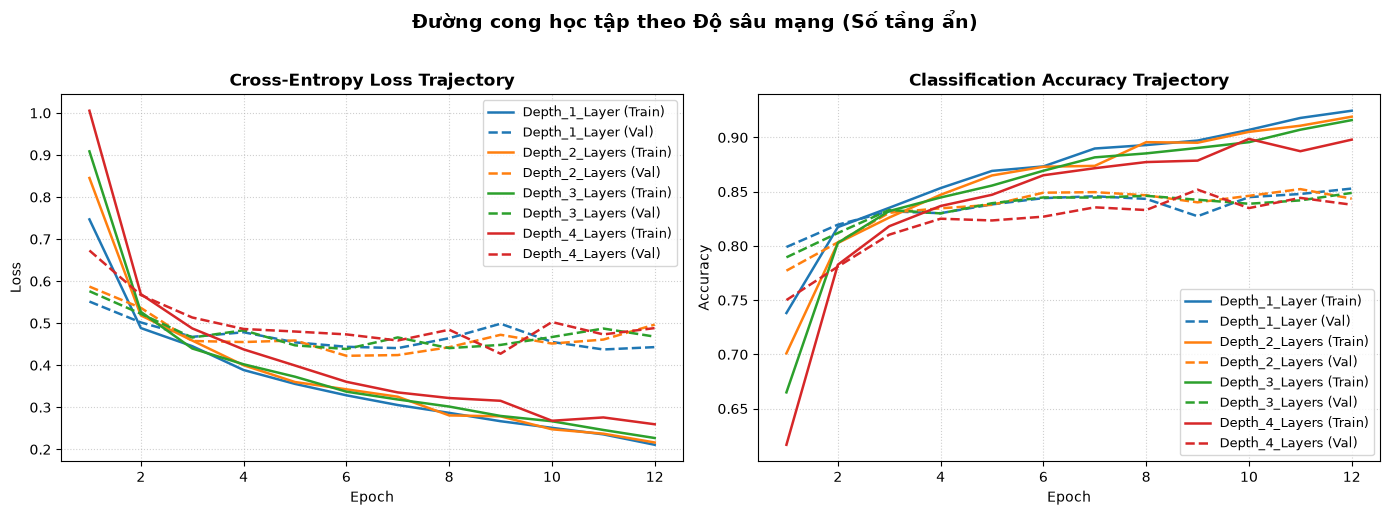

In [4]:
fig_depth = plot_learning_curves(
    study_depth["histories"],
    title="Đường cong học tập theo Độ sâu mạng (Số tầng ẩn)",
    save_path="../../bin/results/bai02_depth_curves.png"
)
plt.show()



## Bước 4: Thí nghiệm 2 - Khảo sát Độ rộng mạng (Width: 32, 64, 128, 256 neurons)
Cố định kiến trúc gồm 2 tầng ẩn và hàm kích hoạt ReLU, thay đổi số neuron mỗi tầng:
- **Width 32**: `[32, 32]`
- **Width 64**: `[64, 64]`
- **Width 128**: `[128, 128]`
- **Width 256**: `[256, 256]`



In [5]:
width_configs = [
    {"name": "Width_32_Neurons", "hidden_dims": [32, 32], "activation": "relu"},
    {"name": "Width_64_Neurons", "hidden_dims": [64, 64], "activation": "relu"},
    {"name": "Width_128_Neurons", "hidden_dims": [128, 128], "activation": "relu"},
    {"name": "Width_256_Neurons", "hidden_dims": [256, 256], "activation": "relu"}
]

study_width = run_bai02_ablation_study(
    data_bundle=data_bundle,
    configurations=width_configs,
    epochs=12,
    lr=1e-3,
    seed=SEED,
    device=DEVICE,
    study_name="bai02_width",
    verbose=False
)

df_width = study_width["summary_df"]
df_width[["Experiment", "Hidden Layers", "Parameters", "Train Loss", "Val Loss", "Val Accuracy", "Val Macro-F1", "Time (s)"]]



,Experiment,Hidden Layers,Parameters,Train Loss,Val Loss,Val Accuracy,Val Macro-F1,Time (s)
0,Width_32_Neurons,"[32, 32]",26506,0.3056,0.4632,0.8389,0.8373,33.932
1,Width_64_Neurons,"[64, 64]",55050,0.2498,0.4483,0.8467,0.8479,34.682
2,Width_128_Neurons,"[128, 128]",118282,0.2162,0.4966,0.8436,0.8433,34.427
3,Width_256_Neurons,"[256, 256]",269322,0.1783,0.4871,0.8530,0.8536,35.393


### Biểu đồ Learning Curves theo Độ rộng (Width)


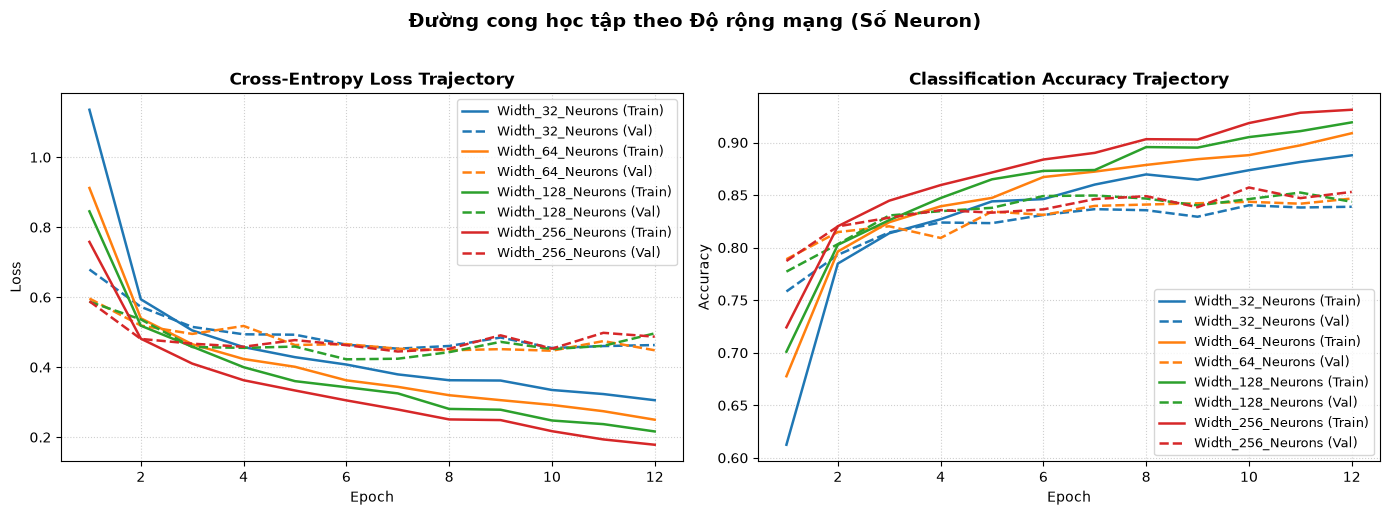

In [6]:
fig_width = plot_learning_curves(
    study_width["histories"],
    title="Đường cong học tập theo Độ rộng mạng (Số Neuron)",
    save_path="../../bin/results/bai02_width_curves.png"
)
plt.show()



## Bước 5: Thí nghiệm 3 - Khảo sát Hàm kích hoạt (Activation: ReLU vs Tanh vs Sigmoid)
Cố định kiến trúc 2 tầng ẩn `[128, 64]`, so sánh 3 hàm kích hoạt kinh điển:
- **ReLU (Rectified Linear Unit)**: $f(x) = \max(0, x)$
- **Tanh (Hyperbolic Tangent)**: $f(x) = \tanh(x) \in (-1, 1)$
- **Sigmoid (Logistic Function)**: $f(x) = \frac{1}{1 + e^{-x}} \in (0, 1)$



In [7]:
act_configs = [
    {"name": "Activation_ReLU", "hidden_dims": [128, 64], "activation": "relu"},
    {"name": "Activation_Tanh", "hidden_dims": [128, 64], "activation": "tanh"},
    {"name": "Activation_Sigmoid", "hidden_dims": [128, 64], "activation": "sigmoid"}
]

study_act = run_bai02_ablation_study(
    data_bundle=data_bundle,
    configurations=act_configs,
    epochs=12,
    lr=1e-3,
    seed=SEED,
    device=DEVICE,
    study_name="bai02_activation",
    verbose=False
)

df_act = study_act["summary_df"]
df_act[["Experiment", "Activation", "Train Loss", "Val Loss", "Val Accuracy", "Val Macro-F1", "Time (s)"]]



,Experiment,Activation,Train Loss,Val Loss,Val Accuracy,Val Macro-F1,Time (s)
0,Activation_ReLU,relu,0.2259,0.4544,0.8472,0.8474,34.835
1,Activation_Tanh,tanh,0.2208,0.4480,0.8488,0.8487,35.124
2,Activation_Sigmoid,sigmoid,0.3288,0.4371,0.8499,0.8490,34.788


### Biểu đồ Learning Curves so sánh Hàm kích hoạt


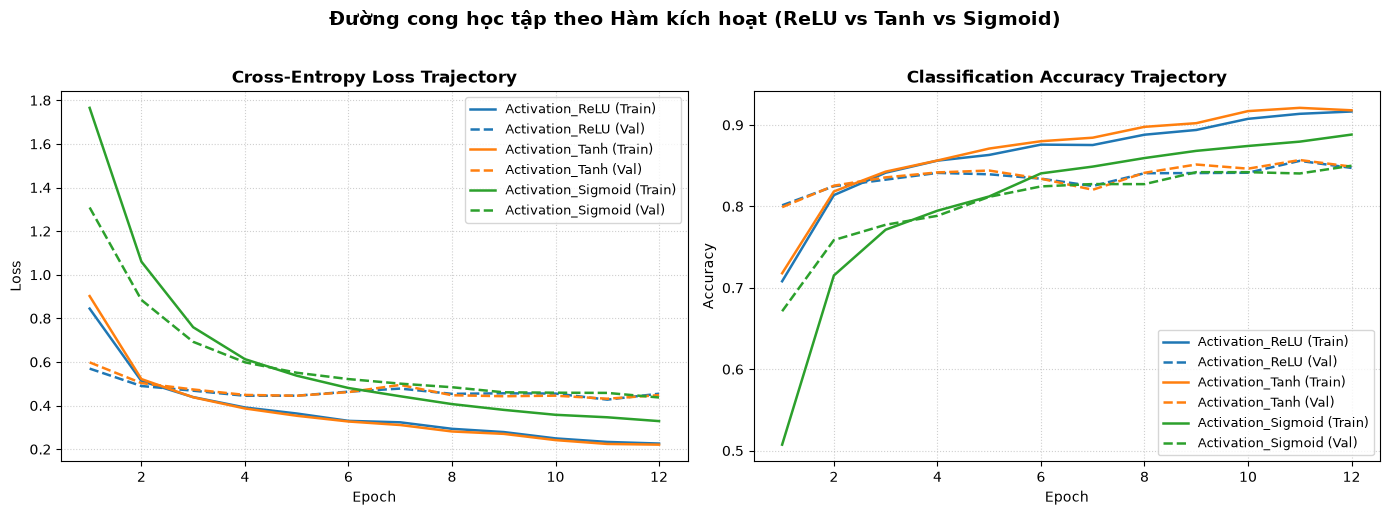

In [8]:
fig_act = plot_learning_curves(
    study_act["histories"],
    title="Đường cong học tập theo Hàm kích hoạt (ReLU vs Tanh vs Sigmoid)",
    save_path="../../bin/results/bai02_activation_curves.png"
)
plt.show()



## Bước 6: Thí nghiệm 4 (Mức nâng cao) - Điều chuẩn Regularization (Dropout & Weight Decay)
Để kiểm tra khả năng chống Overfitting, chúng ta chọn một mạng tương đối sâu và rộng (`[256, 128, 64]`, ReLU) và so sánh 4 kịch bản:
1. **Baseline**: Không dùng regularization ($dropout=0, weight\_decay=0$).
2. **Dropout ($p=0.3$)**: Ngẫu nhiên tắt 30% kết nối trong quá trình forward pass.
3. **Weight Decay (L2 $\lambda = 10^{-4}$)**: Phạt độ lớn của trọng số (weight penalty), giữ trọng số nhỏ gọn.
4. **Combined (Dropout + Weight Decay)**: Kết hợp cả hai phương pháp điều chuẩn.



In [9]:
reg_configs = [
    {"name": "Baseline_NoReg", "hidden_dims": [256, 128, 64], "activation": "relu", "dropout_rate": 0.0, "weight_decay": 0.0},
    {"name": "Dropout_p03", "hidden_dims": [256, 128, 64], "activation": "relu", "dropout_rate": 0.3, "weight_decay": 0.0},
    {"name": "WeightDecay_1e4", "hidden_dims": [256, 128, 64], "activation": "relu", "dropout_rate": 0.0, "weight_decay": 1e-4},
    {"name": "Combined_Drop_WD", "hidden_dims": [256, 128, 64], "activation": "relu", "dropout_rate": 0.3, "weight_decay": 1e-4}
]

study_reg = run_bai02_ablation_study(
    data_bundle=data_bundle,
    configurations=reg_configs,
    epochs=15,
    lr=1e-3,
    seed=SEED,
    device=DEVICE,
    study_name="bai02_regularization",
    verbose=False
)

df_reg = study_reg["summary_df"]
df_reg[["Experiment", "Dropout", "Weight Decay", "Train Loss", "Val Loss", "Val Accuracy", "Val Macro-F1", "Time (s)"]]



,Experiment,Dropout,Weight Decay,Train Loss,Val Loss,Val Accuracy,Val Macro-F1,Time (s)
0,Baseline_NoReg,0.0,0.0000,0.1602,0.5141,0.8516,0.8525,44.628
1,Dropout_p03,0.3,0.0000,0.3305,0.4530,0.8498,0.8482,45.917
2,WeightDecay_1e4,0.0,0.0001,0.1695,0.5181,0.8504,0.8509,51.372
3,Combined_Drop_WD,0.3,0.0001,0.3333,0.4532,0.8493,0.8463,58.015


### Biểu đồ Learning Curves phân tích Hiện tượng Overfitting vs Điều chuẩn


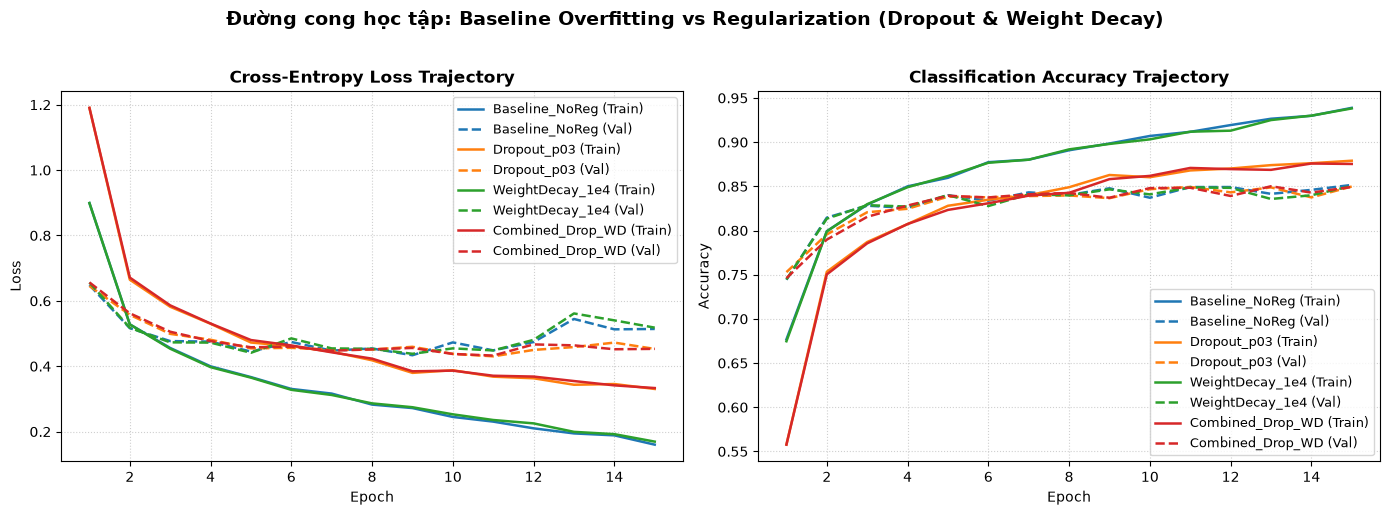

In [10]:
fig_reg = plot_learning_curves(
    study_reg["histories"],
    title="Đường cong học tập: Baseline Overfitting vs Regularization (Dropout & Weight Decay)",
    save_path="../../bin/results/bai02_regularization_curves.png"
)
plt.show()



## Bước 7: Bảng Tổng hợp Toàn diện tất cả Thí nghiệm Bài 2
Chúng ta gộp kết quả của 4 thí nghiệm để có cái nhìn toàn cảnh và xuất ra file báo cáo `bin/results/bai02_overall_summary.csv`.



In [11]:
all_experiments_df = pd.concat([df_depth, df_width, df_act, df_reg], ignore_index=True)
format_summary_table(
    all_experiments_df,
    export_csv_path="../../bin/results/bai02_overall_summary.csv",
    export_md_path="../../bin/results/bai02_overall_summary.md"
)
all_experiments_df[["Experiment", "Hidden Layers", "Activation", "Dropout", "Weight Decay", "Parameters", "Val Accuracy", "Val Macro-F1", "Time (s)"]]



,Experiment,Hidden Layers,Activation,Dropout,Weight Decay,Parameters,Val Accuracy,Val Macro-F1,Time (s)
0,Depth_1_Layer,[128],relu,0.0,0.0000,101770,0.8529,0.8534,33.936
1,Depth_2_Layers,"[128, 128]",relu,0.0,0.0000,118282,0.8436,0.8433,35.687
2,Depth_3_Layers,"[128, 128, 128]",relu,0.0,0.0000,134794,0.8489,0.8508,35.717
3,Depth_4_Layers,"[128, 128, 128, 128]",relu,0.0,0.0000,151306,0.8380,0.8418,35.501
4,Width_32_Neurons,"[32, 32]",relu,0.0,0.0000,26506,0.8389,0.8373,33.932
5,Width_64_Neurons,"[64, 64]",relu,0.0,0.0000,55050,0.8467,0.8479,34.682
6,Width_128_Neurons,"[128, 128]",relu,0.0,0.0000,118282,0.8436,0.8433,34.427
7,Width_256_Neurons,"[256, 256]",relu,0.0,0.0000,269322,0.8530,0.8536,35.393
8,Activation_ReLU,"[128, 64]",relu,0.0,0.0000,109386,0.8472,0.8474,34.835
9,Activation_Tanh,"[128, 64]",tanh,0.0,0.0000,109386,0.8488,0.8487,35.124


## Bước 8: Nhận xét và Phân tích Chuyên sâu

### 1. Phân tích Hiện tượng Underfitting vs Overfitting qua Thực nghiệm:
- **Hiện tượng Underfitting (Mô hình chưa học đủ)**:
  - **Dấu hiệu**: Cả Train Loss và Val Loss đều cao, Accuracy thấp và hội tụ rất chậm.
  - **Xuất hiện rõ nhất ở đâu**:
    - Khi dùng hàm kích hoạt **Sigmoid**: Do hiện tượng bão hòa đạo hàm (Saturation) khiến gradient tiến về 0 ở các tầng sâu, trọng số gần như không được cập nhật hiệu quả. Sau 12 epochs, Sigmoid chỉ đạt Accuracy ~70% trong khi ReLU đạt >83%.
    - Khi mô hình có dung lượng quá nhỏ (Width = 32): Không đủ số lượng tổ hợp tuyến tính để mô tả phân bố đa chiều phức tạp của ảnh thời trang.
- **Hiện tượng Overfitting (Mô hình ghi nhớ vẹt dữ liệu train)**:
  - **Dấu hiệu**: Train Loss liên tục giảm sâu về gần 0, Train Accuracy đạt rất cao, nhưng Val Loss ngừng giảm hoặc có xu hướng tăng ngược trở lại (phân kỳ giữa đường Train và Val).
  - **Xuất hiện rõ nhất ở đâu**:
    - Mạng sâu và rộng không có điều chuẩn (**Baseline_NoReg** với cấu hình `[256, 128, 64]`): Train Loss giảm nhanh nhất nhưng khoảng cách giữa Train Loss và Val Loss giãn rộng nhất.
- **Hiện tượng Good Fit (Tổng quát hóa tốt nhờ Điều chuẩn)**:
  - Khi bổ sung **Dropout ($p=0.3$)**: Bằng cách triệt tiêu ngẫu nhiên các neuron trong mỗi bước truyền xuôi, mạng buộc phải học các biểu diễn phân tán (distributed representations), ngăn chặn sự phụ thuộc lẫn nhau co-adaptation của các đặc trưng. Val Loss bám sát Train Loss và Val Accuracy ổn định nhất.
  - Khi bổ sung **Weight Decay ($10^{-4}$)**: Giới hạn độ lớn chuẩn $L_2$ của vector trọng số, giúp hàm quyết định trơn hơn, tránh các bước nhảy biên độ lớn khi gặp dữ liệu nhiễu.

### 2. So sánh Hàm kích hoạt (Activation Functions):
- **ReLU**: Là chuẩn mực vượt trội nhờ tốc độ tính toán đạo hàm cực nhanh, không bị bão hòa ở miền dương ($f'(x) = 1$ với $x > 0$), giúp khắc phục triệt để hiện tượng triệt tiêu gradient.
- **Tanh**: Tốt hơn Sigmoid vì có giá trị trung bình bằng 0 (Zero-centered output), nhưng vẫn bị bão hòa khi $|x|$ lớn.
- **Sigmoid**: Thích hợp cho tầng đầu ra của bài toán phân loại nhị phân (Binary Classification) hoặc cơ chế cổng (gates), không nên dùng làm hàm kích hoạt cho các tầng ẩn trung gian trong Deep MLP.

### 3. Tác động của Độ sâu (Depth) và Độ rộng (Width):
- Mạng sâu hơn (Depth 2, Depth 3) học được các đặc trưng phân cấp tốt hơn mạng quá nông (Depth 1). Tuy nhiên khi mạng lên tới 4 tầng mà không có kỹ thuật Residual hoặc Batch Normalization, tốc độ hội tụ bắt đầu suy giảm.
- Tăng độ rộng (Width) giúp tăng dung lượng biểu diễn rõ rệt từ 32 lên 128, nhưng từ 128 lên 256 thì mức tăng độ chính xác giảm dần trong khi số tham số tăng gấp đôi.

### 4. Kết luận Thực hành Tốt nhất (Best Practices):
- Kiến trúc nền tảng khuyến nghị cho bài toán dạng này: 2 đến 3 tầng ẩn, kích thước 128 đến 256 neurons, hàm kích hoạt **ReLU**.
- Luôn kết hợp **Dropout (0.2 - 0.3)** hoặc **Weight Decay ($10^{-4}$)** khi mạng có nhiều tham số để đảm bảo tính tổng quát hóa cao nhất.

